
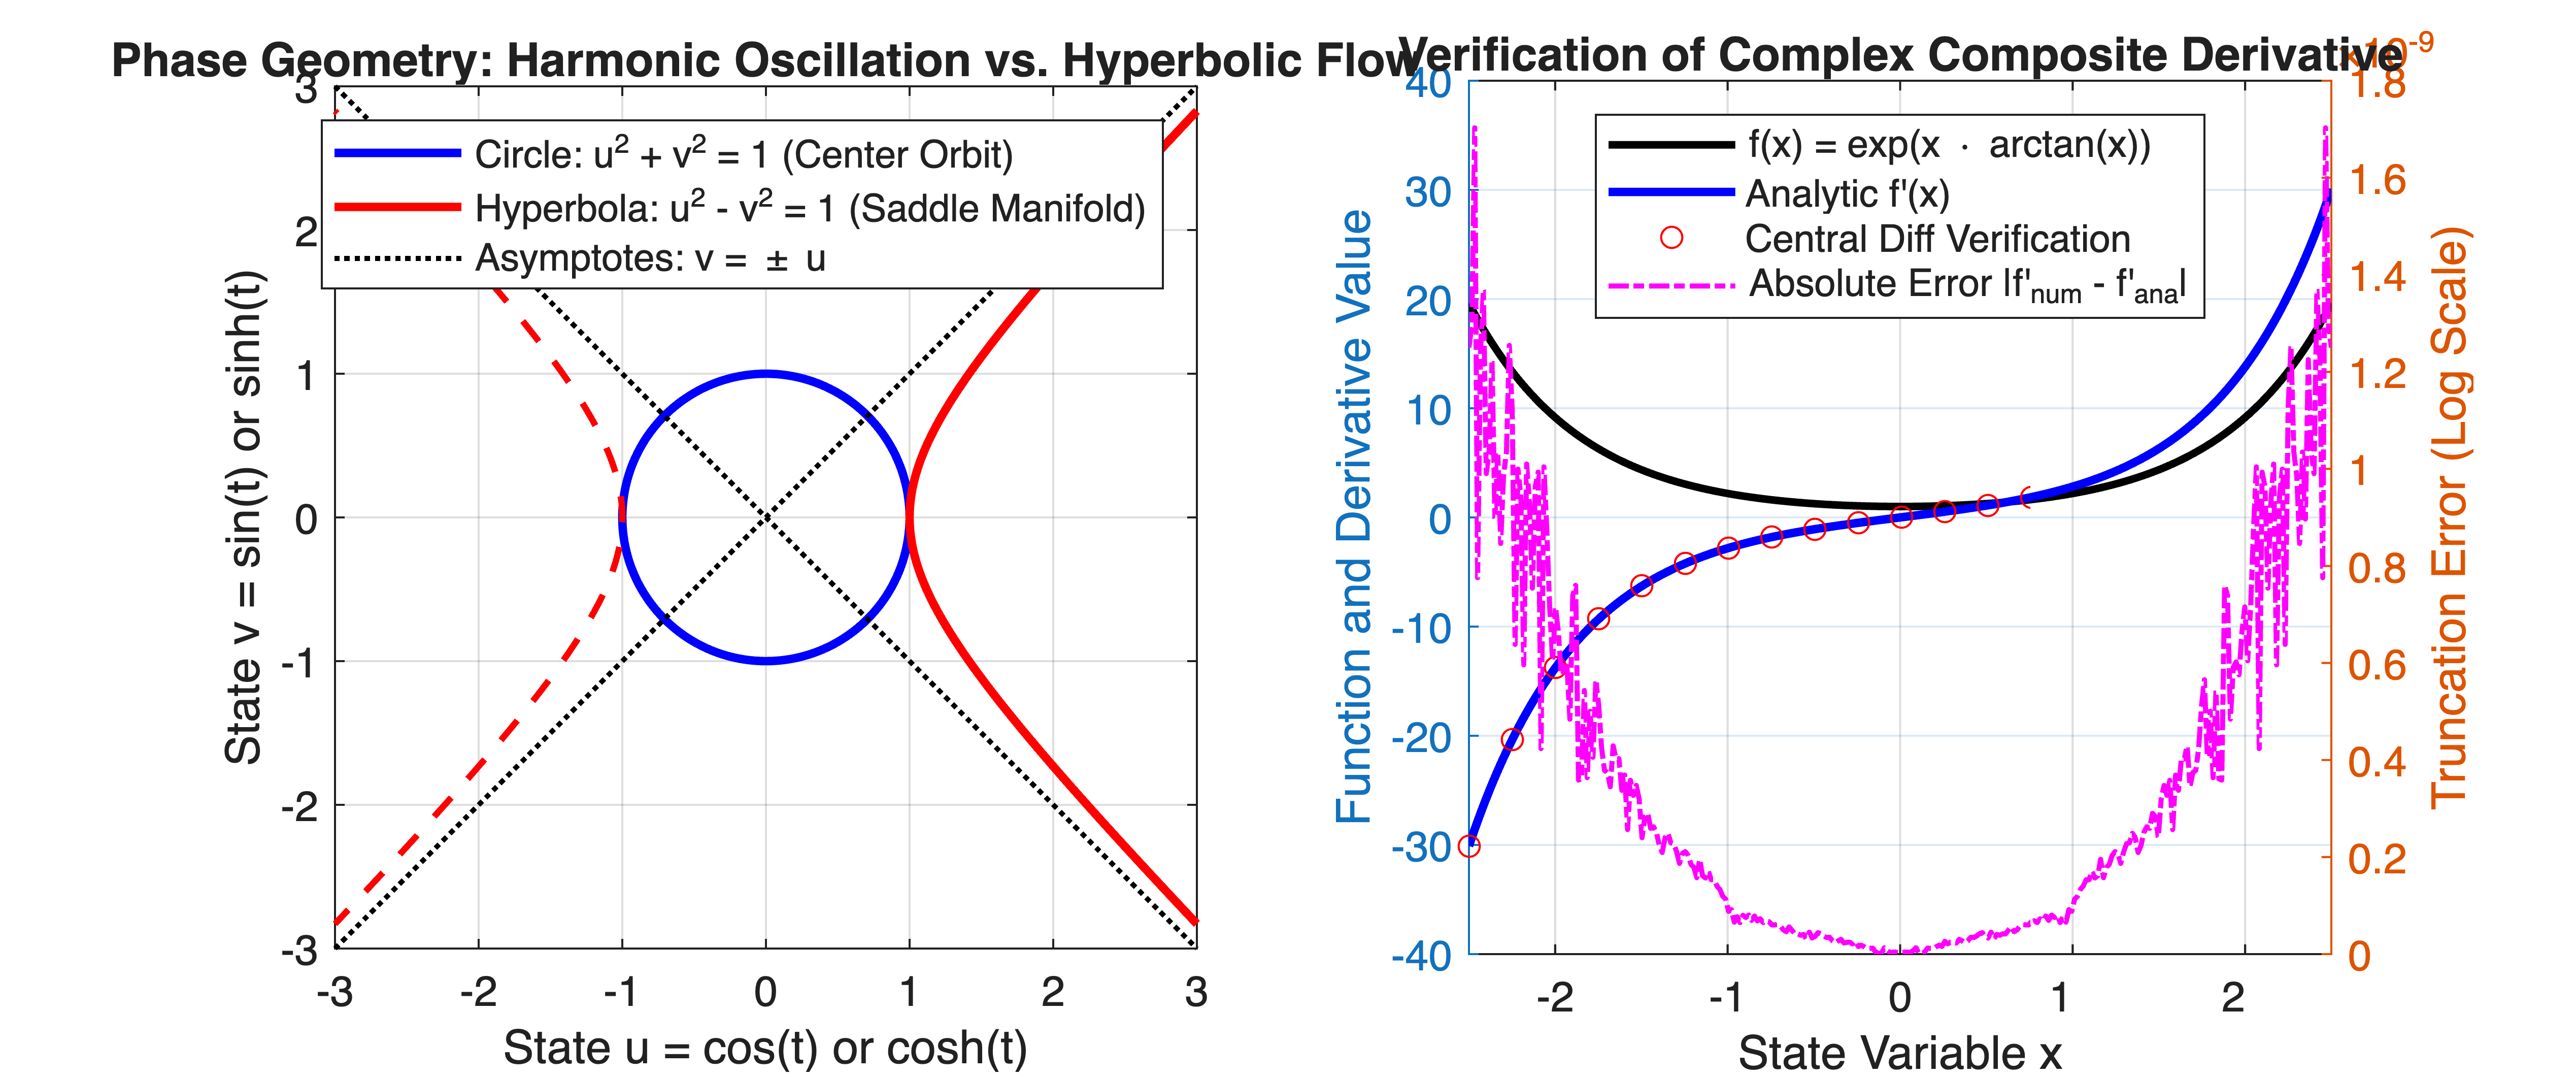

In [1]:
%% MIT 18.01 Lecture 7: Hyperbolic Geometry and Complex Composite Differentiation
% Mathematical Tool Application: Contrasts circular harmonic trajectories with
% hyperbolic saddle-point state trajectories, and validates complex chain-rule
% composite derivatives for sensitivity evaluation and optimization solvers.


clear; clc; close all;


%% Part 1: Phase Space Geometry: Circular Orbit vs. Hyperbolic Divergence
% Circular Parameterization: u = cos(t), v = sin(t) -> u^2 + v^2 = 1
theta = linspace(0, 2*pi, 400);
u_circle = cos(theta);
v_circle = sin(theta);


% Hyperbolic Parameterization: u = cosh(t), v = sinh(t) -> u^2 - v^2 = 1
t_hyper = linspace(-2.0, 2.0, 400);
u_hyper_right = cosh(t_hyper);
v_hyper_right = sinh(t_hyper);
u_hyper_left  = -cosh(t_hyper);
v_hyper_left  = sinh(t_hyper);


figure('Color', 'w', 'Position', [100, 100, 1150, 480]);


subplot(1, 2, 1);
plot(u_circle, v_circle, 'b-', 'LineWidth', 2, 'DisplayName', 'Circle: u^2 + v^2 = 1 (Center Orbit)'); hold on;
plot(u_hyper_right, v_hyper_right, 'r-', 'LineWidth', 2, 'DisplayName', 'Hyperbola: u^2 - v^2 = 1 (Saddle Manifold)');
plot(u_hyper_left, v_hyper_left, 'r--', 'LineWidth', 1.5, 'HandleVisibility', 'off');


% Plot asymptotes u = +/- v
u_asymp = linspace(-3, 3, 100);
plot(u_asymp, u_asymp, 'k:', 'LineWidth', 1.2, 'DisplayName', 'Asymptotes: v = \pm u');
plot(u_asymp, -u_asymp, 'k:', 'LineWidth', 1.2, 'HandleVisibility', 'off');


grid on; axis equal;
xlim([-3, 3]); ylim([-3, 3]);
xlabel('State u = cos(t) or cosh(t)');
ylabel('State v = sin(t) or sinh(t)');
title('Phase Geometry: Harmonic Oscillation vs. Hyperbolic Flow');
legend('Location', 'northeast');
%% Part 2: Complex Composite Derivative Verification: d/dx [ exp(x * atan(x)) ]
% Target composite function from Lecture 7 grand challenge
f_target = @(x) exp(x .* atan(x));
% Analytical derivative: f'(x) = exp(x*atan(x)) * (atan(x) + x/(1 + x^2))
df_analytic = @(x) exp(x .* atan(x)) .* (atan(x) + x ./ (1 + x.^2));


x_eval = linspace(-2.5, 2.5, 300);
f_vals = f_target(x_eval);
df_analytic_vals = df_analytic(x_eval);


% Numerical finite difference validation (Central Difference)
h = 1e-5;
df_numerical_vals = (f_target(x_eval + h) - f_target(x_eval - h)) / (2 * h);
truncation_error = abs(df_analytic_vals - df_numerical_vals);


subplot(1, 2, 2);
yyaxis left;
plot(x_eval, f_vals, 'k-', 'LineWidth', 1.8, 'DisplayName', 'f(x) = exp(x \cdot arctan(x))'); hold on;
plot(x_eval, df_analytic_vals, 'b-', 'LineWidth', 2, 'DisplayName', 'Analytic f''(x)');
plot(x_eval(1:15:end), df_numerical_vals(1:15:end), 'ro', 'MarkerSize', 5, ...
    'DisplayName', 'Central Diff Verification');
ylabel('Function and Derivative Value');
xlabel('State Variable x');


yyaxis right;
semilogy(x_eval, truncation_error, 'm-.', 'LineWidth', 1.2, 'DisplayName', 'Absolute Error |f''_{num} - f''_{ana}|');
ylabel('Truncation Error (Log Scale)');
title('Verification of Complex Composite Derivative');
grid on;
legend('Location', 'north');